# Giai đoạn 1b: Thêm biến đại diện (điểm cháy, lịch)

**Loại công việc: chuẩn bị dữ liệu (data engineering)**, chưa phải analysis, mining hay ML.
Đầu vào: bảng giờ sạch từ notebook 01. Đầu ra:
- `data/clean/hanoi_hourly_enriched.parquet`: bảng giờ + điểm cháy theo ngày + biến lịch.
- `data/clean/hanoi_daily.parquet`: **bảng theo ngày** (một dòng = một ngày), là đơn vị phân tích của Giai đoạn 3.

Hai nhóm biến thêm vào, đúng tinh thần brief (biến có cùng độ phân giải ngày/giờ, không dùng số liệu theo năm):
1. **Điểm cháy vệ tinh** NASA FIRMS: đại diện cho đốt rơm rạ, đốt nương rẫy, đốt mở.
2. **Lịch**: Tết Nguyên đán, các đợt giãn cách COVID-19 ở Hà Nội: đại diện cho thay đổi giao thông và sản xuất.

In [1]:
from pathlib import Path
import os, time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

TZ = "Asia/Ho_Chi_Minh"
LAT, LON = 21.0219, 105.8188          # trạm Đại sứ quán Mỹ (theo metadata OpenAQ)
BASE = Path(os.environ.get("HANOI_AQ_DIR", "."))
RAW, CLEAN, REPORT = BASE / "data" / "raw", BASE / "data" / "clean", BASE / "reports"
(RAW / "firms").mkdir(parents=True, exist_ok=True)

hourly = pd.read_parquet(CLEAN / "hanoi_hourly_clean.parquet")
print(hourly.shape, hourly.index.min(), "->", hourly.index.max(), hourly.index.tz)

(80592, 28) 2016-01-30 00:00:00+07:00 -> 2025-04-09 23:00:00+07:00 Asia/Ho_Chi_Minh


## 1. Điểm cháy NASA FIRMS

**Nguồn:** FIRMS (Fire Information for Resource Management System) công bố file điểm cháy **theo quốc gia, theo năm**, tải trực tiếp không cần MAP_KEY:
`https://firms.modaps.eosdis.nasa.gov/data/country/<cảm biến>/<năm>/<cảm biến>_<năm>_Vietnam.csv`.
Mỗi dòng là một điểm ảnh (pixel) vệ tinh phát hiện nhiệt bất thường, với toạ độ, ngày giờ quét (**UTC**), độ tin cậy, FRP (Fire Radiative Power, công suất bức xạ của đám cháy, MW, gợi ý độ lớn đám cháy) và `type` (0 = cháy thực vật giả định, 2 = nguồn nhiệt cố định như nhà máy, 3 = ngoài khơi).

**Hai cảm biến:**
- **VIIRS S-NPP** (độ phân giải 375 m): nhạy với đám cháy nhỏ như đốt rơm, phiên bản xử lý thống nhất (v2) cho cả giai đoạn. **Dùng làm biến chính.**
- **MODIS** Terra/Aqua (1 km): chuỗi dài nhất nhưng kém nhạy với đám cháy nhỏ, và phiên bản xử lý đổi qua các năm (6.2 → 6.03 → 61.03), quỹ đạo Terra/Aqua trôi dần sau 2020. Giữ làm biến phụ để đối chiếu.

**Lựa chọn khác:** API theo vùng của FIRMS (cần MAP_KEY, lọc bbox trực tiếp, lấy được cả Nam Trung Quốc và Lào); sản phẩm diện tích cháy MCD64A1 (theo tháng, thô hơn).

**Giới hạn quan trọng:** file quốc gia **chỉ có điểm cháy trong lãnh thổ Việt Nam**. Cháy ở Lào, Bắc Thái Lan, Nam Trung Quốc (nguồn vận chuyển xa vào mùa khô) không có trong dữ liệu này.

Vệ tinh chỉ bay qua vài lần một ngày (VIIRS khoảng 13:30 và 01:30 giờ địa phương) và **không thấy qua mây**. Nên số điểm cháy = 0 vào ngày nhiều mây không có nghĩa là không có cháy.

In [2]:
FIRMS = "https://firms.modaps.eosdis.nasa.gov/data/country/{s}/{y}/{s}_{y}_Vietnam.csv"
SENSORS = ["viirs-snpp", "modis"]
YEARS = range(hourly.index.year.min(), hourly.index.year.max() + 1)

def download_firms(sensor, year):
    out = RAW / "firms" / f"{sensor}_{year}_Vietnam.csv"
    if out.exists() and out.read_bytes()[:8] == b"latitude":
        return out
    for attempt in range(6):          # máy chủ FIRMS hay ngắt kết nối giữa chừng, nên thử lại
        try:
            r = requests.get(FIRMS.format(s=sensor, y=year), timeout=300)
            if r.status_code == 200 and r.content[:8] == b"latitude":
                out.write_bytes(r.content); return out
            print(sensor, year, "HTTP", r.status_code)
        except requests.RequestException as e:
            print(sensor, year, type(e).__name__)
        time.sleep(3 * (attempt + 1))
    raise RuntimeError(f"Không tải được {sensor} {year}")

# Nếu không tải được FIRMS (mạng chặn, máy chủ lỗi) hoặc đặt FIRMS_OFFLINE=1: dùng bảng ngày đã lưu ở lần chạy trước
# (data/clean/firms_daily.csv). Điểm cháy không phụ thuộc vào làm sạch PM2.5, nên dùng lại bảng này là an toàn.
FIRMS_FROM_CACHE = os.environ.get("FIRMS_OFFLINE") == "1"
if not FIRMS_FROM_CACHE:
    try:
        fires_raw = {s: pd.concat([pd.read_csv(download_firms(s, y)) for y in YEARS], ignore_index=True) for s in SENSORS}
        for s, d in fires_raw.items():
            print(s, d.shape, "| phiên bản:", sorted(d["version"].astype(str).unique()), "| ngày cuối:", d["acq_date"].max())
    except RuntimeError as e:
        print("Không tải được FIRMS:", e); FIRMS_FROM_CACHE = True
if FIRMS_FROM_CACHE:
    print("Dùng bảng điểm cháy theo ngày đã lưu:", CLEAN / "firms_daily.csv")

Dùng bảng điểm cháy theo ngày đã lưu: data/clean/firms_daily.csv


### 1.1 Kiểm tra chất lượng và lọc

- **Múi giờ:** `acq_date` + `acq_time` (HHMM) là **UTC**. Đổi sang giờ Hà Nội rồi mới lấy ngày, nếu không các lượt quét đêm (~01:30 giờ VN = 18:30 UTC hôm trước) sẽ bị gán sai ngày.
- **Loại nguồn nhiệt cố định** (`type` = 2, ví dụ nhà máy thép, xi măng) và ngoài khơi (`type` = 3): chỉ giữ `type` = 0 (cháy thực vật/sinh khối), vì brief dùng FIRMS làm đại diện cho đốt sinh khối.
- **Độ tin cậy:** VIIRS bỏ mức `l` (low); MODIS giữ `confidence` ≥ 30 (mức nominal + high theo hướng dẫn FIRMS). Lựa chọn khác: giữ tất cả (nhiều điểm cháy nhỏ thật bị gắn low) hoặc chỉ giữ high.
- **Trùng lặp:** kiểm tra theo (toạ độ, thời điểm, vệ tinh).

In [3]:
def prep(d, sensor):
    d = d.copy()
    t_utc = pd.to_datetime(d["acq_date"] + " " + d["acq_time"].astype(int).astype(str).str.zfill(4), format="%Y-%m-%d %H%M", utc=True)
    d["time_local"] = t_utc.dt.tz_convert(TZ)
    d["date"] = d["time_local"].dt.tz_localize(None).dt.normalize()
    n0 = len(d)
    dup = d.duplicated(["latitude", "longitude", "acq_date", "acq_time", "satellite"]).sum()
    if sensor == "modis":
        conf_ok = d["confidence"] >= 30
    else:
        conf_ok = d["confidence"].astype(str).isin(["n", "h"])
    keep = (d["type"] == 0) & conf_ok
    print(f"{sensor}: {n0} điểm | trùng {dup} | type≠0: {(d['type'] != 0).sum()} | độ tin cậy thấp: {(~conf_ok).sum()} | giữ {keep.sum()}")
    print("   giờ quét địa phương phổ biến:", d["time_local"].dt.hour.value_counts().head(4).to_dict())
    return d[keep]

fires = None if FIRMS_FROM_CACHE else {s: prep(d, s) for s, d in fires_raw.items()}

### 1.2 Vùng không gian

Ba vùng, từ gần đến xa, để Giai đoạn 2–3 xem vùng nào liên hệ mạnh nhất với PM2.5:

| Cột | Vùng | Vì sao |
|---|---|---|
| `*_r100` | bán kính 100 km quanh trạm | đốt rơm ở Hà Nội và các tỉnh giáp ranh |
| `*_rrd` | khung đồng bằng Bắc Bộ: vĩ độ 19.8–21.7°N, kinh độ 105.2–107.1°E | đúng phạm vi brief; khung chữ nhật gần đúng (bao trọn Hà Nội, Vĩnh Phúc, Bắc Ninh, Hưng Yên, Hải Dương, Hải Phòng, Thái Bình, Nam Định, Hà Nam, Ninh Bình, và một phần trung du giáp ranh) |
| `*_north` | toàn miền Bắc Việt Nam (vĩ độ ≥ 19.5°N) | gồm Tây Bắc, nơi đốt nương rẫy mạnh vào tháng 2–4 |

**[GIẢ ĐỊNH]** Dùng khung chữ nhật thay cho ranh giới tỉnh chính xác (cần file shapefile hành chính). Lựa chọn khác: lọc theo đa giác tỉnh (GADM), hoặc theo **hướng** từ trạm (để ghép với hướng gió ở Giai đoạn 3: điểm cháy *ở phía gió thổi tới* mới đáng kể).

Mỗi vùng có 2 số: **số điểm cháy** (`n`) và **tổng FRP** (`frp`, MW). Cũng lưu **phương vị trung bình có trọng số FRP** của các điểm cháy trong 300 km (`bearing300`) để sau này so với hướng gió.

In [4]:
R_EARTH = 6371.0
def haversine_km(lat, lon):
    p1, p2 = np.radians(LAT), np.radians(lat)
    dphi, dl = p2 - p1, np.radians(lon - LON)
    a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R_EARTH * np.arcsin(np.sqrt(a))

def bearing_deg(lat, lon):
    p1, p2 = np.radians(LAT), np.radians(lat)
    dl = np.radians(lon - LON)
    x = np.sin(dl) * np.cos(p2)
    y = np.cos(p1) * np.sin(p2) - np.sin(p1) * np.cos(p2) * np.cos(dl)
    return (np.degrees(np.arctan2(x, y)) + 360) % 360

REGIONS = {
    "r100": lambda d: d["dist_km"] <= 100,
    "rrd": lambda d: d["latitude"].between(19.8, 21.7) & d["longitude"].between(105.2, 107.1),
    "north": lambda d: d["latitude"] >= 19.5,
}
PREFIX = {"viirs-snpp": "viirs", "modis": "modis"}

if FIRMS_FROM_CACHE:
    fire_daily = pd.read_csv(CLEAN / "firms_daily.csv", index_col=0, parse_dates=True)
    fire_daily.index.name = "date"
else:
    daily_fire = []
    for s, d in fires.items():
        d = d.assign(dist_km=haversine_km(d["latitude"], d["longitude"]), brg=bearing_deg(d["latitude"], d["longitude"]))
        p = PREFIX[s]
        for reg, f in REGIONS.items():
            g = d[f(d)].groupby("date").agg(**{f"{p}_n_{reg}": ("frp", "size"), f"{p}_frp_{reg}": ("frp", "sum")})
            daily_fire.append(g)
        # phương vị trung bình (biến tròn: lấy trung bình vector, không trung bình trực tiếp độ)
        near = d[d["dist_km"] <= 300].assign(sx=lambda x: x["frp"] * np.sin(np.radians(x["brg"])),
                                             cx=lambda x: x["frp"] * np.cos(np.radians(x["brg"])))
        b = near.groupby("date")[["sx", "cx"]].sum()
        daily_fire.append(pd.DataFrame({f"{p}_bearing300": (np.degrees(np.arctan2(b["sx"], b["cx"])) + 360) % 360}))

    all_days = pd.date_range(f"{min(YEARS)}-01-01", f"{max(YEARS)}-12-31", freq="D", name="date")
    fire_daily = pd.concat(daily_fire, axis=1, sort=True).reindex(all_days)
    count_cols = [c for c in fire_daily.columns if "_n_" in c or "_frp_" in c]
    fire_daily[count_cols] = fire_daily[count_cols].fillna(0)   # ngày không có điểm nào = 0 (nhưng nhớ: có thể do mây)
fire_daily.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
viirs_n_r100,3653.0,3.7,7.7,0.0,0.0,1.0,4.0,127.0
viirs_frp_r100,3653.0,19.2,51.6,0.0,0.0,0.7,15.0,830.5
viirs_n_rrd,3653.0,4.4,9.3,0.0,0.0,1.0,5.0,151.0
viirs_frp_rrd,3653.0,24.3,67.2,0.0,0.0,1.2,20.1,931.9
viirs_n_north,3653.0,44.9,100.3,0.0,1.0,8.0,37.0,1305.0
viirs_frp_north,3653.0,387.2,989.0,0.0,1.3,46.3,278.5,15596.4
viirs_bearing300,2896.0,210.0,91.4,0.1,158.3,233.9,276.9,359.5
modis_n_r100,3653.0,1.7,5.3,0.0,0.0,0.0,1.0,143.0
modis_frp_r100,3653.0,22.1,73.0,0.0,0.0,0.0,9.6,1946.5
modis_n_rrd,3653.0,2.2,7.3,0.0,0.0,0.0,1.0,194.0


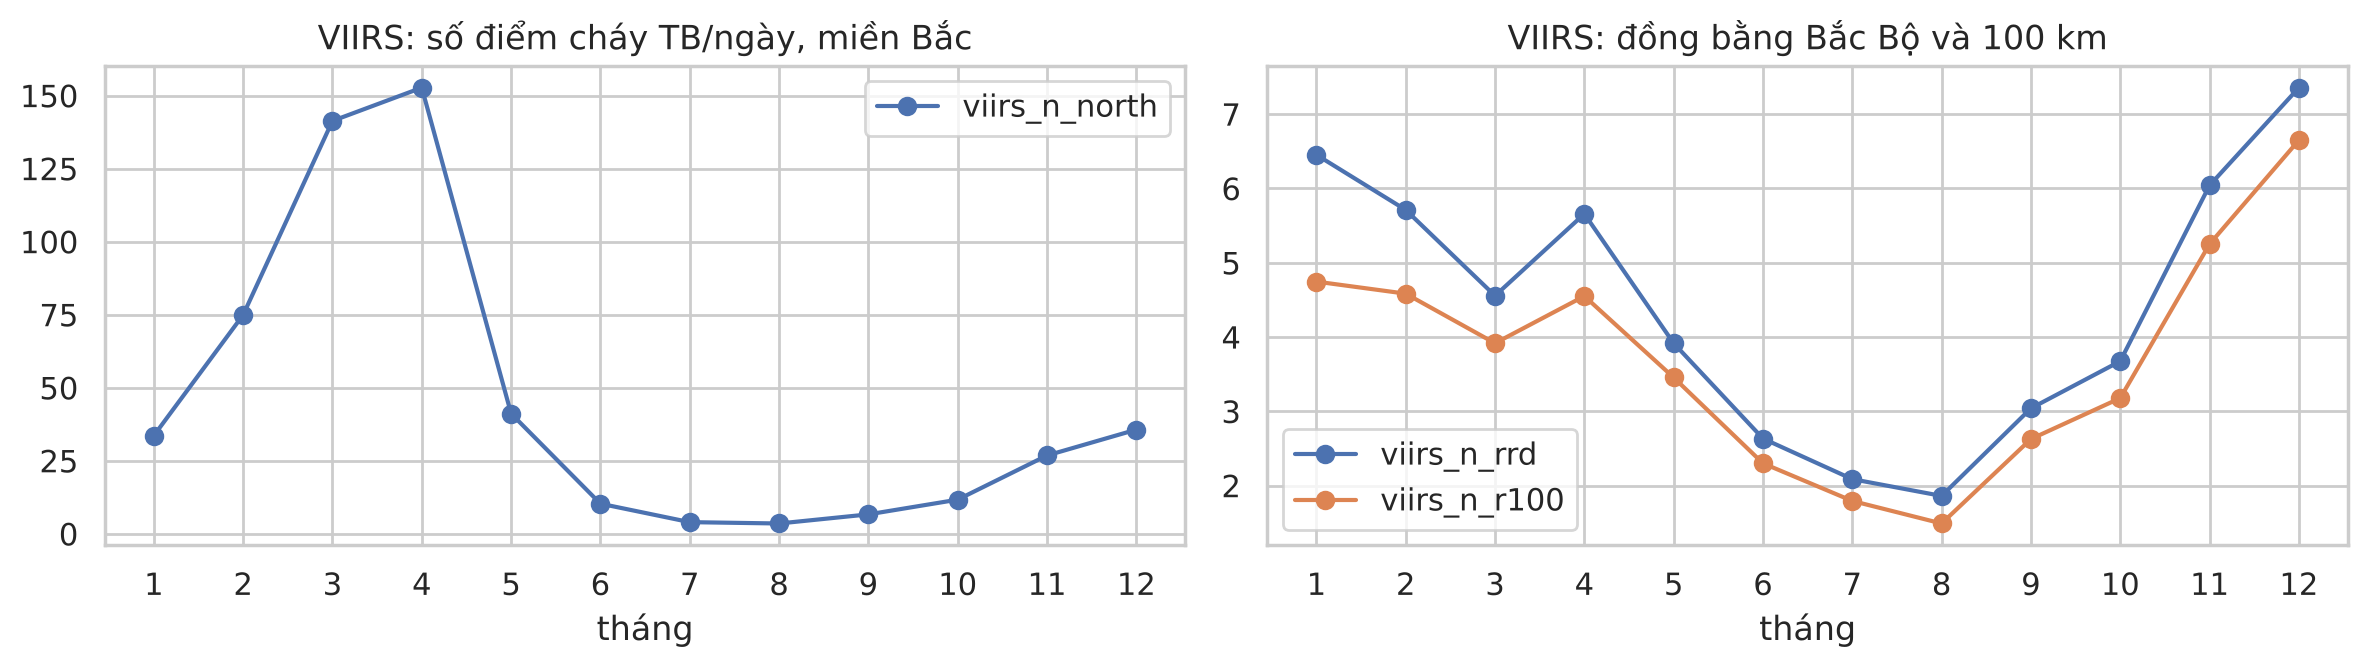

,viirs_n_rrd,modis_n_rrd,viirs_n_north,modis_n_north,tỷ lệ VIIRS/MODIS (miền Bắc)
date,,,,,
2016,1546.0,842.0,23455.0,7277.0,3.2
2017,1364.0,713.0,13459.0,4343.0,3.1
2018,1428.0,412.0,12720.0,3472.0,3.7
2019,1585.0,534.0,21632.0,6113.0,3.5
2020,1216.0,448.0,15541.0,4866.0,3.2
2021,1487.0,669.0,14317.0,4552.0,3.1
2022,1570.0,708.0,11523.0,3376.0,3.4
2023,1827.0,1116.0,21424.0,7396.0,2.9
2024,1597.0,992.0,16606.0,6138.0,2.7


In [5]:
# Kiểm tra: mùa vụ của điểm cháy (kỳ vọng đỉnh tháng 2–4 ở miền Bắc do đốt nương; đỉnh phụ tháng 6 và 10 ở đồng bằng do đốt rơm sau gặt)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
m = fire_daily.groupby(fire_daily.index.month)
m[["viirs_n_north"]].mean().plot(ax=ax[0], marker="o", title="VIIRS: số điểm cháy TB/ngày, miền Bắc")
m[["viirs_n_rrd", "viirs_n_r100"]].mean().plot(ax=ax[1], marker="o", title="VIIRS: đồng bằng Bắc Bộ và 100 km")
for a in ax: a.set_xlabel("tháng"); a.set_xticks(range(1, 13))
plt.tight_layout(); plt.savefig(REPORT / "firms_seasonality.png", dpi=120); plt.show()

# So VIIRS với MODIS theo năm: nếu tỷ lệ đổi đột ngột thì có thể do thay đổi cảm biến chứ không phải do cháy thật
yr = fire_daily.groupby(fire_daily.index.year)[["viirs_n_rrd", "modis_n_rrd", "viirs_n_north", "modis_n_north"]].sum()
yr["tỷ lệ VIIRS/MODIS (miền Bắc)"] = (yr["viirs_n_north"] / yr["modis_n_north"]).round(1)
yr

## 2. Biến lịch

### 2.1 Tết Nguyên đán
Ngày mùng 1 Tết tính bằng thư viện `lunardate` (lịch âm Trung Quốc). Lịch âm Việt Nam dùng múi giờ UTC+7 nên thỉnh thoảng lệch 1 ngày so với lịch Trung Quốc (ví dụ Tết 1985), nhưng giai đoạn 2016–2025 không có năm nào lệch. Đã đối chiếu: các ngày dưới khớp với gai pháo hoa Giao thừa trong dữ liệu PM2.5 (notebook 01) và lịch nghỉ Tết chính thức (ví dụ Tết Nhâm Dần 2022: nghỉ 31/1–4/2/2022, mùng 1 là 1/2).

Biến tạo ra:
- `tet_day`: số ngày so với mùng 1 Tết gần nhất (−15 … +15, ngoài khoảng đó để trống). Cho phép xem PM2.5 thay đổi thế nào trước, trong và sau Tết.
- `is_tet_holiday`: **[GIẢ ĐỊNH]** từ 28 tháng Chạp (−2) đến mùng 5 (+4), xấp xỉ kỳ nghỉ chính thức 5–9 ngày. Lịch nghỉ chính thức thay đổi theo từng năm và chưa được tra cứu đủ cho cả 10 năm.

In [6]:
from lunardate import LunarDate
TET = {y: pd.Timestamp(LunarDate(y, 1, 1).to_solar_date()) for y in range(min(YEARS), max(YEARS) + 2)}
pd.Series({y: d.date() for y, d in TET.items()}, name="mùng 1 Tết")

2016    2016-02-08
2017    2017-01-28
2018    2018-02-16
2019    2019-02-05
2020    2020-01-25
2021    2021-02-12
2022    2022-02-01
2023    2023-01-22
2024    2024-02-10
2025    2025-01-29
2026    2026-02-17
Name: mùng 1 Tết, dtype: object

### 2.2 Giãn cách xã hội COVID-19 ở Hà Nội

Chỉ ghi các đợt **giãn cách toàn thành phố theo Chỉ thị 16** (mức chặt nhất, giao thông giảm mạnh), có áp dụng cho quận Ba Đình nơi đặt trạm. Đã tra cứu từ báo chí và văn bản chính thức:

| Đợt | Bắt đầu | Kết thúc | Nguồn |
|---|---|---|---|
| 2020 | 00:00 01/04/2020 (Chỉ thị 16/CT-TTg ngày 31/3/2020) | 00:00 23/04/2020 (trừ Mê Linh, Thường Tín) | [Vietnamplus](https://www.vietnamplus.vn/ha-noi-tiep-tuc-thuc-hien-gian-cach-xa-hoi-it-nhat-den-ngay-22-4/634775.vnp), [LSVN](https://lsvn.vn/ha-noi-ngung-cach-ly-xa-hoi-tu-0h-ngay-23-4-a37807.html) |
| 2021 | 06:00 24/07/2021 (Chỉ thị 17/CT-UBND) | gia hạn đến 06:00 23/8, rồi 06:00 6/9 (Công điện 19) | [Tạp chí Tòa án](https://tapchitoaan.vn/ha-noi-gian-cach-theo-chi-thi-16-tu-6h-ngay-247), [Báo Quốc tế](https://baoquocte.vn/ha-noi-tiep-tuc-gian-cach-xa-hoi-den-6h-ngay-69-155717.html) |
| 2021 (phân vùng) | 06:00 06/09/2021 | 06:00 21/09/2021: Vùng 1 gồm 10 quận nội thành **có Ba Đình** tiếp tục Chỉ thị 16 (Chỉ thị 20/CT-UBND) | [LuatVietnam](https://luatvietnam.vn/tin-van-ban-moi/10-quan-cua-ha-noi-tiep-tuc-gian-cach-theo-chi-thi-16-186-32679-article.html) |

Biến tạo ra: `lockdown` (bool, theo giờ chính xác) và `lockdown_phase` (`2020`, `2021_toan_tp`, `2021_vung1`).
Không đưa vào: các biện pháp nhẹ hơn (Chỉ thị 15, đóng cửa hàng quán tháng 5/2021, phong tỏa cục bộ), vì mức ảnh hưởng tới giao thông khó định lượng. Từ 6:00 21/9/2021, Hà Nội chuyển sang Chỉ thị 22 (mức Chỉ thị 15 và tăng cường).

Lưu ý: trạm PM2.5 **thiếu dữ liệu từ 19/1 đến đầu tháng 6/2021** (xem notebook 01), không ảnh hưởng hai đợt trên.

In [7]:
LOCKDOWNS = [
    ("2020",          "2020-04-01 00:00", "2020-04-23 00:00"),
    ("2021_toan_tp",  "2021-07-24 06:00", "2021-09-06 06:00"),
    ("2021_vung1",    "2021-09-06 06:00", "2021-09-21 06:00"),
]
lockdown_tbl = pd.DataFrame(LOCKDOWNS, columns=["phase", "start", "end"])
lockdown_tbl[["start", "end"]] = lockdown_tbl[["start", "end"]].apply(lambda c: pd.to_datetime(c).dt.tz_localize(TZ))
lockdown_tbl

,phase,start,end
0,2020,2020-04-01 00:00:00+07:00,2020-04-23 00:00:00+07:00
1,2021_toan_tp,2021-07-24 06:00:00+07:00,2021-09-06 06:00:00+07:00
2,2021_vung1,2021-09-06 06:00:00+07:00,2021-09-21 06:00:00+07:00


## 3. Ghép vào bảng giờ và tạo bảng ngày

- Bảng giờ: điểm cháy là số **theo ngày**, nên mọi giờ trong ngày nhận cùng giá trị (ghép theo `date` địa phương). Lịch ghép theo giờ chính xác.
- Bảng ngày: thời tiết tổng hợp theo ngày (trung bình, tổng mưa, biên độ nhiệt, hướng gió trung bình vector, lớp biên); PM2.5 trung bình 24 giờ, chỉ tính khi đủ ≥ 18 giờ hợp lệ (giống notebook 01); kèm max, số giờ hợp lệ, và **đường cong 24 giờ** (`pm25_h00`…`pm25_h23` từ `pm25_filled`) để clustering ở Giai đoạn 3.
- Thêm cột **trễ 1 ngày** cho điểm cháy (`*_lag1`), vì khói cần thời gian vận chuyển và vệ tinh quét lúc 13:30 nên đám cháy chiều tối chỉ thấy vào hôm sau.
- Thêm `exceed_who` (> 15 µg/m³) và `exceed_qcvn` (> 50 µg/m³) cho trung bình 24 giờ. **Cần kiểm chứng lại ngưỡng** trước khi dùng (brief đã ghi chú).

In [8]:
fire_cols = list(fire_daily.columns)
fd = fire_daily.copy()
lag_src = [c for c in fire_cols if c.startswith("viirs_n_") or c.startswith("viirs_frp_")]
for c in lag_src:
    fd[c + "_lag1"] = fd[c].shift(1)

h = hourly.copy()
h["date"] = pd.to_datetime(h["date"])
h = h.join(fd, on="date")

# Lịch
tet_dates = pd.Series(TET).sort_values()
def tet_offset(d):
    diffs = (d - tet_dates).dt.days
    k = diffs.abs().idxmin()
    v = diffs[k]
    return v if abs(v) <= 15 else np.nan
day_index = pd.DatetimeIndex(h["date"].unique())
tet_map = pd.Series([tet_offset(d) for d in day_index], index=day_index)
h["tet_day"] = h["date"].map(tet_map)
h["is_tet_holiday"] = h["tet_day"].between(-2, 4)

h["lockdown_phase"] = pd.Series(pd.NA, index=h.index, dtype="string")
for _, r in lockdown_tbl.iterrows():
    h.loc[(h.index >= r["start"]) & (h.index < r["end"]), "lockdown_phase"] = r["phase"]
h["lockdown"] = h["lockdown_phase"].notna()

print(h.shape)
print("Số giờ giãn cách:", h.groupby("lockdown_phase").size().to_dict(),
      "| trong đó có PM2.5:", h[h["lockdown"]].groupby("lockdown_phase")["pm25"].count().to_dict())
print("Số ngày Tết (holiday) có ≥18h PM2.5:",
      int((h[h["is_tet_holiday"]].groupby("date")["pm25"].count() >= 18).sum()))

(80592, 52)
Số giờ giãn cách: {'2020': 528, '2021_toan_tp': 1056, '2021_vung1': 360} | trong đó có PM2.5: {'2020': 500, '2021_toan_tp': 794, '2021_vung1': 359}
Số ngày Tết (holiday) có ≥18h PM2.5: 55


In [9]:
g = h.groupby("date")
daily = pd.DataFrame({
    "n_valid_h": g["pm25"].count(),
    "pm25_mean_raw": g["pm25"].mean(),
    "pm25_max": g["pm25"].max(),
    "n_spike_h": g["flag_spike"].sum(),
})
daily["day_ok"] = daily["n_valid_h"] >= 18
daily["pm25_mean"] = daily["pm25_mean_raw"].where(daily["day_ok"])
daily = daily.drop(columns="pm25_mean_raw")

# Đường cong 24 giờ (dùng pm25_filled: đã nội suy các khoảng ≤ 3 giờ). Ngày còn NaN trong đường cong sẽ bị loại khi clustering.
curve = h.pivot_table(index="date", columns="hour", values="pm25_filled", aggfunc="first").reindex(columns=range(24))
curve.columns = [f"pm25_h{c:02d}" for c in curve.columns]
daily = daily.join(curve)
daily["curve_complete"] = curve.notna().all(axis=1).reindex(daily.index, fill_value=False)

# Thời tiết theo ngày (giờ địa phương). Hướng gió là biến tròn nên tính từ trung bình vector u, v.
wx_daily = g.agg(t_mean=("temperature_2m", "mean"), t_min=("temperature_2m", "min"), t_max=("temperature_2m", "max"),
                 rh_mean=("relative_humidity_2m", "mean"), precip_sum=("precipitation", "sum"),
                 pressure_mean=("surface_pressure", "mean"), cloud_mean=("cloud_cover", "mean"),
                 sw_sum=("shortwave_radiation", "sum"), ws_mean=("wind_speed_10m", "mean"),
                 u_mean=("wind_u", "mean"), v_mean=("wind_v", "mean"),
                 blh_mean=("boundary_layer_height", "mean"), blh_max=("boundary_layer_height", "max"),
                 blh_n=("boundary_layer_height", "count"))
wx_daily["t_range"] = wx_daily["t_max"] - wx_daily["t_min"]   # biên độ nhiệt ngày: đêm lạnh + ngày nắng gợi ý nghịch nhiệt ban đêm
wx_daily["wind_dir_mean"] = (np.degrees(np.arctan2(-wx_daily["u_mean"], -wx_daily["v_mean"])) + 360) % 360   # hướng gió THỔI TỪ
wx_daily.loc[wx_daily["blh_n"] < 24, ["blh_mean", "blh_max"]] = np.nan   # nửa đầu 2024 nguồn thiếu lớp biên
daily = daily.join(wx_daily.drop(columns="blh_n"))
day_vars = fd.columns.tolist()
daily = daily.join(fd[day_vars])
cal = h.groupby("date").agg(tet_day=("tet_day", "first"), is_tet_holiday=("is_tet_holiday", "first"),
                            lockdown_hours=("lockdown", "sum"))
daily = daily.join(cal)
daily["lockdown"] = daily["lockdown_hours"] >= 12
daily["year"], daily["month"], daily["dow"] = daily.index.year, daily.index.month, daily.index.dayofweek
daily["is_weekend"] = daily["dow"] >= 5
daily["exceed_who"] = daily["pm25_mean"] > 15
daily["exceed_qcvn"] = daily["pm25_mean"] > 50

print(daily.shape, "| ngày đủ (≥18h):", int(daily["day_ok"].sum()), "| ngày có đường cong 24h đầy đủ:", int(daily["curve_complete"].sum()))
daily.loc[daily["day_ok"], ["pm25_mean", "viirs_n_rrd", "viirs_n_north", "modis_n_rrd"]].describe().round(1)

(3358, 75) | ngày đủ (≥18h): 2322 | ngày có đường cong 24h đầy đủ: 2265


,pm25_mean,viirs_n_rrd,viirs_n_north,modis_n_rrd
count,2322.0,2322.0,2322.0,2322.0
mean,45.4,4.6,48.2,2.3
std,27.4,9.8,106.5,8.2
min,4.7,0.0,0.0,0.0
25%,26.1,0.0,1.0,0.0
50%,37.6,1.0,9.0,0.0
75%,56.8,5.0,40.8,1.0
max,176.0,151.0,1305.0,194.0


### 3.1 Kiểm tra nhanh sau khi ghép (chưa phải phân tích)

Chỉ để chắc chắn phép ghép hợp lý: các con số dưới là **mối liên hệ thô**, chưa kiểm soát mùa và thời tiết, nên **không** kết luận gì ở đây. Phân tích thật thuộc Giai đoạn 2.

Tương quan Spearman (xếp hạng, ít nhạy với ngoại lai) giữa PM2.5 ngày và điểm cháy:
viirs_n_r100        0.30
viirs_n_rrd         0.31
viirs_n_north       0.36
viirs_n_rrd_lag1    0.27
modis_n_rrd         0.18
Name: pm25_mean, dtype: float64


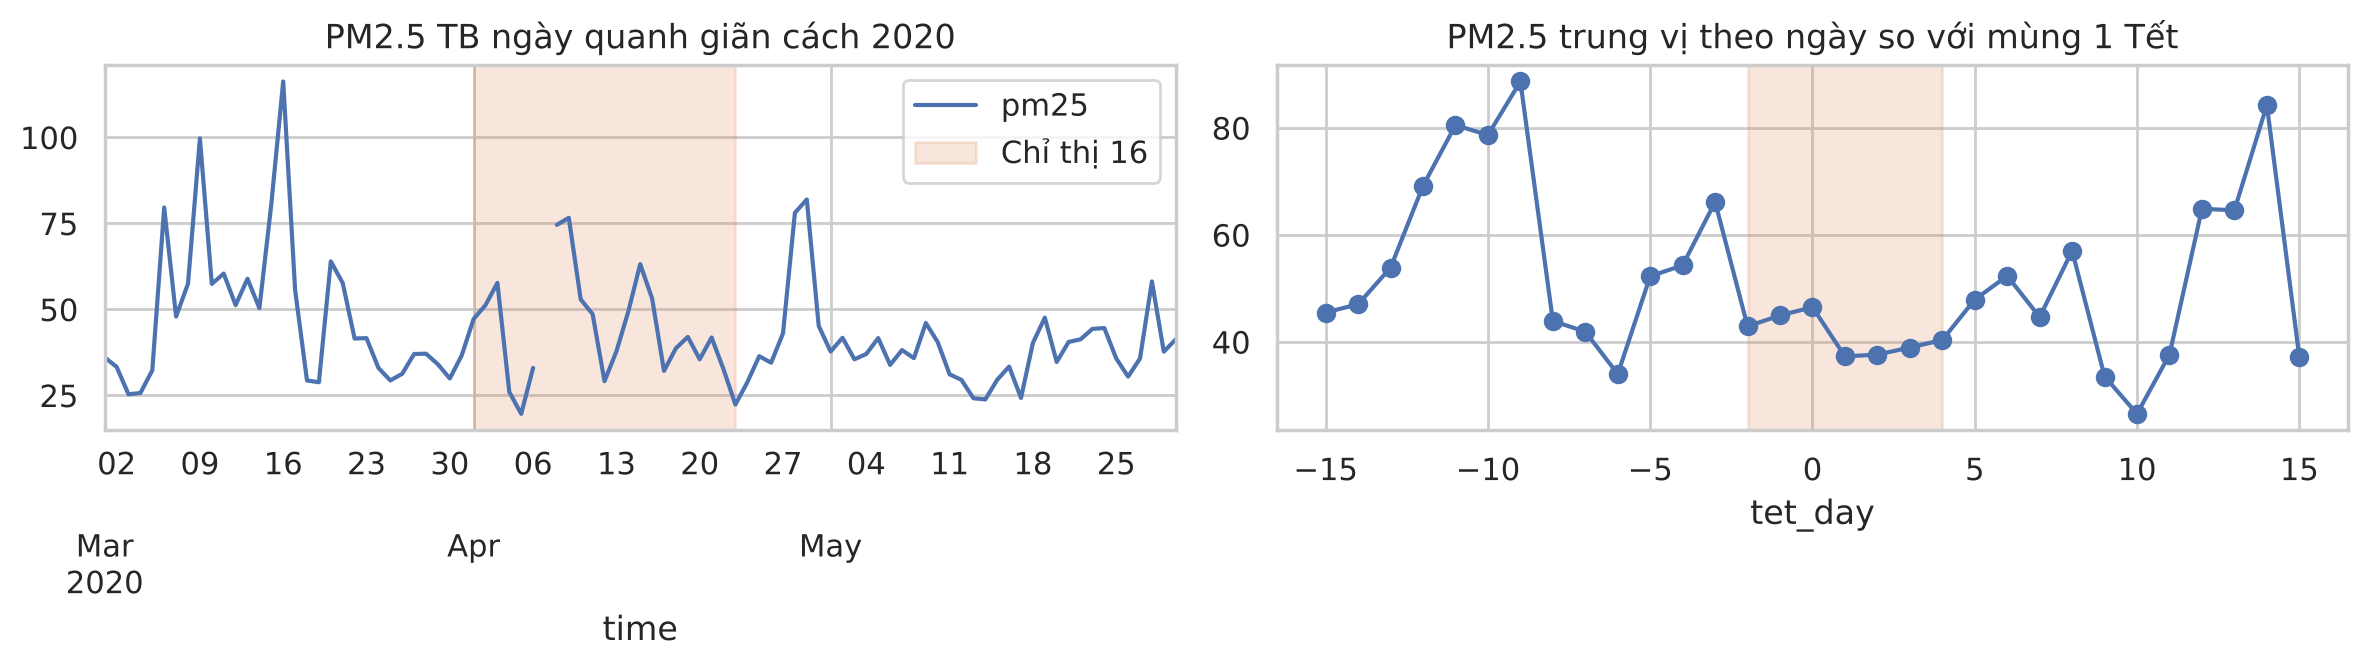

In [10]:
ok = daily[daily["day_ok"]]
print("Tương quan Spearman (xếp hạng, ít nhạy với ngoại lai) giữa PM2.5 ngày và điểm cháy:")
print(ok[["pm25_mean", "viirs_n_r100", "viirs_n_rrd", "viirs_n_north", "viirs_n_rrd_lag1", "modis_n_rrd"]]
      .corr(method="spearman")["pm25_mean"].round(2).drop("pm25_mean"))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
sub = h[(h.index >= "2020-03-01") & (h.index < "2020-05-31")]
sub["pm25"].resample("D").mean().plot(ax=ax[0], title="PM2.5 TB ngày quanh giãn cách 2020")
ax[0].axvspan(pd.Timestamp("2020-04-01", tz=TZ), pd.Timestamp("2020-04-23", tz=TZ), color="C1", alpha=0.2, label="Chỉ thị 16")
ax[0].legend()
td = ok[ok["tet_day"].notna()].groupby("tet_day")["pm25_mean"].median()
td.plot(ax=ax[1], marker="o", title="PM2.5 trung vị theo ngày so với mùng 1 Tết")
ax[1].axvspan(-2, 4, color="C1", alpha=0.2)
plt.tight_layout(); plt.savefig(REPORT / "calendar_check.png", dpi=120); plt.show()

## 4. Lưu

In [11]:
h.to_parquet(CLEAN / "hanoi_hourly_enriched.parquet")
daily.to_parquet(CLEAN / "hanoi_daily.parquet")
daily.reset_index().to_csv(CLEAN / "hanoi_daily.csv", index=False)
fire_daily.to_csv(CLEAN / "firms_daily.csv")
print("hourly:", h.shape, "| daily:", daily.shape)

hourly: (80592, 52) | daily: (3358, 75)


## Ghi chú giới hạn
- FIRMS file quốc gia chỉ có điểm cháy **trong Việt Nam**; không có Lào, Thái Lan, Nam Trung Quốc.
- Vệ tinh không thấy qua mây và chỉ quét vài lần mỗi ngày: số điểm cháy là **chỉ số tương đối**, không phải tổng số đám cháy.
- MODIS đổi phiên bản xử lý giữa các năm; so sánh xu hướng nhiều năm nên dùng VIIRS.
- Khung "đồng bằng Bắc Bộ" là hình chữ nhật xấp xỉ.
- Kỳ nghỉ Tết là cửa sổ xấp xỉ (−2 … +4 ngày), chưa theo lịch nghỉ chính thức từng năm.
- Chỉ có 3 đợt giãn cách, tổng khoảng 80 ngày: đủ để mô tả, không đủ để khái quát.
- Tất cả là **mối liên hệ**, không phải nhân quả.